# Reading SST-1M raw data (zfits) with the `SST1MEventSource`

This notebook shows how to read the SST-1M raw data files (R0, `*.fits.fz`, written by the DigiCam
camera server) with the ctapipe event source of sst1mpipe, [sst1mpipe.io.sst1m_event_source.SST1MEventSource](https://sst-1m-collaboration.github.io/sst1mpipe/event_sources.html#sst1mpipe.io.sst1m_event_source.SST1MEventSource),
and how to explore what it gives you:

1. Opening a file: through the generic `ctapipe.io.EventSource` or the [SST1MEventSource](https://sst-1m-collaboration.github.io/sst1mpipe/event_sources.html#sst1mpipe.io.sst1m_event_source.SST1MEventSource) directly
2. Run level information: telescope, run, target, pointing, observation / scheduling blocks, DigiCam configuration, subarray
3. Looping over the events and exploring the containers (`index`, `trigger`, `r0`, `monitoring`)
4. Visualising the waveforms, the camera images and the trigger traces
5. Some run level summaries (event types, trigger rate)
6. Under the hood: the same file read directly with `protozfits`

The files used here are the test files distributed with sst1mpipe (`sst1mpipe/resources/test_data/zfits`, stored with git LFS:
run `git lfs pull` if they are only pointers). Replace `input_file` by any SST-1M raw data file.

In [1]:
import collections

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits
from astropy.table import Table
from ctapipe.containers import EventType
from ctapipe.io import EventSource
from ctapipe.visualization import CameraDisplay

from sst1mpipe.io.containers import CameraEventType
from sst1mpipe.io.sst1m_event_source import SST1MEventSource
from sst1mpipe.resources import TEST_DATA_DIR

## 1. Opening a file

The test data directory contains a few short runs of both telescopes: a dark run, transitions between two wobbles
and Mrk 421 observations. The file names follow `SST1M<telescope>_<date>_<run>.fits.fz`.

In [2]:
zfits_dir = TEST_DATA_DIR / "zfits"
for path in sorted(zfits_dir.iterdir()):
    print(f"{path.name:32s} TARGET = {fits.getheader(path, 'Events').get('TARGET')}")

SST1M1_20260120_1179.fits.fz     TARGET = MRK421_W1,166.994800,38.105300
SST1M1_20260121_0206.fits.fz     TARGET = Transition
SST1M2_20260119_0007.fits.fz     TARGET = DARK
SST1M2_20260120_1102.fits.fz     TARGET = MRK421_W1,166.994800,38.105300
SST1M2_20260121_0585.fits.fz     TARGET = Transition


In [3]:
# Mrk 421 observation (wobble W1) of the telescope SST1M-2: 35 events
input_file = zfits_dir / "SST1M2_20260120_1102.fits.fz"

[SST1MEventSource](https://sst-1m-collaboration.github.io/sst1mpipe/event_sources.html#sst1mpipe.io.sst1m_event_source.SST1MEventSource) is registered as a ctapipe I/O plugin (entry point `ctapipe_io` in `pyproject.toml`), so the generic
`ctapipe.io.EventSource` recognises the SST-1M files by itself ([SST1MEventSource.is_compatible](https://sst-1m-collaboration.github.io/sst1mpipe/event_sources.html#sst1mpipe.io.sst1m_event_source.SST1MEventSource.is_compatible) checks that the file
has an `Events` table of `DataModel.CameraEvent` protobuf messages):

In [4]:
print("is_compatible:", SST1MEventSource.is_compatible(input_file))

source = EventSource(input_file, max_events=10)
print(type(source))

is_compatible: True


<class 'sst1mpipe.io.sst1m_event_source.SST1MEventSource'>


You can also instantiate it explicitly, which lets you pass its options (ctapipe traitlets), e.g. `max_events`,
a manual pointing ([pointing_ra](https://sst-1m-collaboration.github.io/sst1mpipe/event_sources.html#sst1mpipe.io.sst1m_event_source.SST1MEventSource.pointing_ra), [pointing_dec](https://sst-1m-collaboration.github.io/sst1mpipe/event_sources.html#sst1mpipe.io.sst1m_event_source.SST1MEventSource.pointing_dec), in deg) which overrides the `TARGET` field of the file,
or the wrongly connected camera modules ([swapped_modules](https://sst-1m-collaboration.github.io/sst1mpipe/event_sources.html#sst1mpipe.io.sst1m_event_source.SST1MEventSource.swapped_modules)). Use `help(SST1MEventSource)` or the
[documentation of the event sources](https://sst-1m-collaboration.github.io/sst1mpipe/event_sources.html) for the full list.
The event source reads a **single file**: loop over the files to read several runs.

In [5]:
for name, trait in SST1MEventSource.class_traits(config=True).items():
    print(f"{name:28s} {trait.help[:90]}")

allowed_tels                 list of allowed tel_ids, others will be ignored. If None, all telescopes in the input stre
focal_length_choice          Which focal length to use for the camera frame transformations.
input_url                    Path to the input file containing events.
max_events                   Maximum number of events that will be read from the file
pointing_dec                 Pointing declination in deg. Overrides the TARGET field of the file.
pointing_ra                  Pointing right ascension in deg. Overrides the TARGET field of the file.
swapped_modules              Wrongly connected modules: the pixels of the two modules are swapped for the events of the


## 2. Run level information

Everything which does not change from event to event is available as attributes of the event source,
without reading any event.

In [6]:
print("telescope id   :", source.tel_id)
print("run id (obs_id):", source.run_id, " run number:", source.run_number)
print("target         :", source.target)
print("wobble         :", source.wobble)
print("pointing (ICRS):", source.pointing)
print("manual pointing:", source.pointing_manual)
print("pedestal events:", source.pedestal_event_type)
print("SWAT event ids :", source.swat_event_ids_available)
print("data levels    :", source.datalevels)
print("simulation     :", source.is_simulation)

telescope id   : 22
run id (obs_id): 202601201102  run number: 1102
target         : MRK421
wobble         : W1
pointing (ICRS): <SkyCoord (ICRS): (ra, dec) in deg
    (166.9948, 38.1053)>
manual pointing: False
pedestal events: EventType.SKY_PEDESTAL
SWAT event ids : True
data levels    : (<DataLevel.R0: 1>,)
simulation     : False


### Observation and scheduling blocks

They follow the ctapipe data model and are written in the DL1 files by `sst1mpipe-process`. The observation block is a
`SST1MObservationBlockContainer` (with the `target` and `wobble` of the run in addition to the ctapipe fields),
the start and duration of the run come from the `DATE` and `DATEEND` fields of the file header.

In [7]:
observation_block = source.observation_blocks[source.run_id]
for key, value in observation_block.items():
    print(f"{key:26s} {value}")

obs_id                     202601201102
sb_id                      202601201102
producer_id                SST1M-22
state                      ObservationBlockState.UNKNOWN
subarray_pointing_lat      38.1053 deg
subarray_pointing_lon      166.9948 deg
subarray_pointing_frame    CoordinateFrameType.ICRS
scheduled_duration         nan min
scheduled_start_time       0.0
actual_start_time          2026-01-21T03:06:31.000
actual_duration            0.0 min
target                     MRK421
wobble                     W1


In [8]:
scheduling_block = source.scheduling_blocks[source.run_id]
for key, value in scheduling_block.items():
    print(f"{key:26s} {value}")

sb_id                      202601201102
sb_type                    SchedulingBlockType.OBSERVATION
producer_id                SST1M-22
observing_mode             ObservingMode.WOBBLE
pointing_mode              PointingMode.TRACK


### The subarray

The `SubarrayDescription` only contains the telescope of the file. It gives the optics and the camera
(geometry, readout: sampling rate, number of samples...).

In [9]:
subarray = source.subarray
subarray.info()

Subarray : SST1M_miniarray
Num Tels : 1
Footprint: 0.02 km2
Height   : 511.20 m
Lon/Lat  : 14.782501388888885 deg, 49.912441666666666 deg 

     Type      Count Tel IDs
-------------- ----- -------
SST_1M_DigiCam     1 22     


In [10]:
tel = subarray.tel[source.tel_id]
camera = tel.camera
print(tel)
print("pixels           :", camera.geometry.n_pixels)
print("pixel shape      :", camera.geometry.pix_type)
print("sampling rate    :", camera.readout.sampling_rate)
print("reference pulse  :", camera.readout.reference_pulse_shape.shape)
print("focal length     :", tel.optics.equivalent_focal_length)

SST_1M_DigiCam
pixels           : 1296
pixel shape      : PixelShape.HEXAGON
sampling rate    : 0.25 GHz
reference pulse  : (1, 1520)
focal length     : 5.599999904632568 m


### DigiCam configuration

The `DigicamConfig` table of the file (configuration of the DigiCam boards) is read into a `DigicamConfigContainer`.
The arrays have one entry per board slot, 0 for the empty slots.

In [11]:
digicam_config = source.digicam_config
print(digicam_config)

{'digicam_time_nanosec': 247889788,
 'digicam_time_sec': 6865,
 'firmware_card_type': array([0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=uint8),
 'firmware_code': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=uint8),
 'firmware_rev': array([ 0, 39, 39, 39, 39, 39, 39, 39, 39, 39,  0, 39, 39, 39, 39, 39, 39,
       39, 39, 39,  0, 39, 39, 39, 39, 39, 39, 39, 39, 39,  0, 46, 46, 48,
       46, 46, 48, 46, 46], dtype=uint8),
 'firmware_vers': array([0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1], dtype=uint8),
 'gateware_card_type': array([0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=uint8),
 'gateware_code': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0

In [12]:
Table({key: value for key, value in digicam_config.items() if np.ndim(value) == 1})[:12]

protocol_vers,sn,hv,gateware_rev,gateware_vers,gateware_code,gateware_card_type,firmware_rev,firmware_vers,firmware_code,firmware_card_type
uint8,uint32,uint8,uint8,uint8,uint8,uint8,uint8,uint8,uint8,uint8
255,0,0,0,0,0,0,0,0,0,0
1,1120024,2,25,1,0,1,39,1,0,1
1,1120025,2,25,1,0,1,39,1,0,1
1,1110016,1,25,1,0,1,39,1,0,1
1,1120027,2,25,1,0,1,39,1,0,1
1,1120020,2,25,1,0,1,39,1,0,1
1,1120029,2,25,1,0,1,39,1,0,1
1,1120026,2,25,1,0,1,39,1,0,1
1,1120023,2,25,1,0,1,39,1,0,1


## 3. Looping over the events

Iterating over the source gives one `SST1MArrayEventContainer` per camera event. It is a ctapipe `ArrayEventContainer`
whose R0 and monitoring containers have extra SST-1M fields. Only the R0 data, the trigger and the pointing are filled
by the event source: the R1/DL0/DL1 containers are filled later by the calibration and the image processing
(see `sst1mpipe-process`).

The event source should be used as a context manager (it closes the file at the end).

In [13]:
with EventSource(input_file, max_events=3) as source:
    for event in source:
        print(f"count={event.count} obs_id={event.index.obs_id} event_id={event.index.event_id} "
              f"type={event.trigger.event_type.name} tels={event.trigger.tels_with_trigger}")

count=0 obs_id=202601201102 event_id=25085123 type=SUBARRAY tels=[22]
count=1 obs_id=202601201102 event_id=25085126 type=SUBARRAY tels=[22]
count=2 obs_id=202601201102 event_id=25085127 type=SUBARRAY tels=[22]


`event` still holds the last event of the loop. A ctapipe container prints its fields with their description:

In [14]:
print(type(event))
print(list(event.keys()))

<class 'sst1mpipe.io.containers.SST1MArrayEventContainer'>
['index', 'r0', 'r1', 'dl0', 'dl1', 'dl2', 'simulation', 'trigger', 'count', 'monitoring', 'muon']


In [15]:
print(event.index)  # print: the values of the fields
event.index         # repr: the description and default of each field

{'event_id': 25085127, 'obs_id': 202601201102}


ctapipe.containers.EventIndexContainer:
                        obs_id: Observation Block ID with default
                                18446744073709551615
                      event_id: Array Event ID with default 18446744073709551615

### The trigger

`event.trigger.event_type` is the ctapipe `EventType`: `SUBARRAY` for the events triggered by the camera and the
pedestal type of the run for the internal triggers (`SKY_PEDESTAL`, or `DARK_PEDESTAL` / `ELECTRONIC_PEDESTAL` for
the dark / bias runs). The time is the DigiCam clock as an `astropy.time.Time`.

In [16]:
print(event.trigger)
print("time (ISO, UTC):", event.trigger.time.utc.isot)

{'event_type': <EventType.SUBARRAY: 32>,
 'tel': {22: {'event_type': <EventType.SUBARRAY: 32>,
              'n_trigger_pixels': -1,
              'time': <Time object: scale='tai' format='unix_tai' value=1768964826.7517002>,
              'trigger_pixels': None}},
 'tels_with_trigger': [22],
 'time': <Time object: scale='tai' format='unix_tai' value=1768964826.7517002>}
time (ISO, UTC): 2026-01-21T03:06:29.752


### The R0 data of the telescope

`event.r0.tel` is a map `tel_id -> SST1MR0CameraContainer`. In addition to the ctapipe `waveform`
(shape `(n_channels, n_pixels, n_samples)`, one gain channel for DigiCam, pixels sorted by pixel id), it contains the
DigiCam specific fields: the baseline computed by DigiCam (`pedestal`), the pixel flags, the camera event type
(a `CameraEventType` flag), the clocks, and the trigger traces.

In [17]:
tel_id = source.tel_id
r0 = event.r0.tel[tel_id]
print(r0)

{'_event_type': <CameraEventType.PATCH7: 1>,
 'camera_event_number': 3612335,
 'event_time': <Time object: scale='tai' format='unix_tai' value=1768964826.7517002>,
 'gps_time': None,
 'pedestal': array([286.9375, 180.625 , 201.625 , ..., 181.1875, 233.    , 194.6875]),
 'pixel_flags': array([1, 1, 1, ..., 1, 1, 1], dtype=uint16),
 'trigger_input_traces': array([[ 8,  2,  3, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0,  0],
       [18, 12,  9, ...,  0,  0,  0],
       ...,
       [ 0,  0,  0, ..., 15, 31, 39],
       [ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ..., 27, 38, 21]], dtype=uint8),
 'trigger_output_muon': array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8),
 'trigger_output_patch19': array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0,

In [18]:
# a quick overview of all the fields: type and shape
for key, value in r0.items():
    shape = getattr(value, "shape", "")
    dtype = getattr(value, "dtype", type(value).__name__)
    print(f"{key:24s} {str(dtype):12s} {shape}")

waveform                 int16        (1, 1296, 50)
pixel_flags              uint16       (1296,)
pedestal                 float64      (1296,)
camera_event_number      int          
event_time               Time         ()
gps_time                 NoneType     
_event_type              CameraEventType 
trigger_input_traces     uint8        (432, 50)
trigger_output_patch7    uint8        (432, 50)
trigger_output_patch19   uint8        (432, 50)
trigger_output_muon      uint8        (432, 50)


In [19]:
print("camera event number:", r0.camera_event_number)
print("camera event type  :", r0.event_type, "->", repr(r0.event_type))
print("is internal trigger:", CameraEventType.INTERNAL in r0.event_type)
print("event time (TAI)   :", r0.event_time.unix_tai, "s")
print("GPS time           :", r0.gps_time)
print("baseline (ADC)     :", r0.pedestal[:5], "...")
print("pixel flags        :", np.unique(r0.pixel_flags, return_counts=True))

camera event number: 3612335
camera event type  : CameraEventType.PATCH7 -> <CameraEventType.PATCH7: 1>
is internal trigger: False
event time (TAI)   : 1768964826.7517002 s
GPS time           : None
baseline (ADC)     : [286.9375 180.625  201.625  176.375  194.3125] ...
pixel flags        : (array([1], dtype=uint16), array([1296]))


### The monitoring

The pointing in RA / Dec of the run is filled for each event. The altitude / azimuth of the telescope and the
camera monitoring (pedestal statistics...) are filled by the monitoring source `SST1MMonitoringSource`
from the output of `sst1mpipe-monitoring`, so they are empty here.

In [20]:
pointing = event.monitoring.pointing
print("RA :", pointing.array_ra.to(u.deg))
print("Dec:", pointing.array_dec.to(u.deg))
print("Alt:", pointing.array_altitude, "(from the monitoring source)")

RA : 166d59m41.28s
Dec: 38d06m19.08s
Alt: nan rad (from the monitoring source)


## 4. Visualising an event

Let's take the brightest triggered (`SUBARRAY`) event and the first pedestal event of the run.

In [21]:
def max_signal(event):
    # largest signal above the DigiCam baseline in the camera (ADC)
    r0 = next(iter(event.r0.tel.values()))
    return (r0.waveform[0] - r0.pedestal[:, None]).max()

shower_event, pedestal_event = None, None
with EventSource(input_file) as source:
    for event in source:
        event_type = event.trigger.event_type
        if event_type == EventType.SUBARRAY and (shower_event is None or max_signal(event) > max_signal(shower_event)):
            shower_event = event
        if event_type == source.pedestal_event_type and pedestal_event is None:
            pedestal_event = event

print(shower_event.index, shower_event.trigger.event_type)
print(pedestal_event.index, pedestal_event.trigger.event_type)

{'event_id': 25085157, 'obs_id': 202601201102} EventType.SUBARRAY
{'event_id': 25085129, 'obs_id': 202601201102} EventType.SKY_PEDESTAL


### Waveforms

The waveforms are in ADC counts, with the DigiCam baseline (`pedestal`) not subtracted. We plot the brightest
pixels of the triggered event (largest signal above baseline) and a few pixels of the pedestal event.

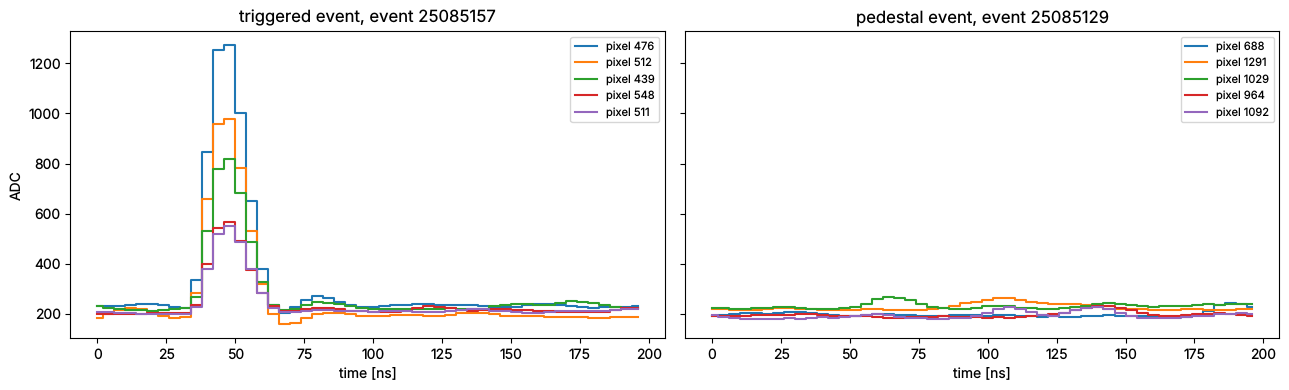

In [22]:
geometry = subarray.tel[tel_id].camera.geometry
sampling_rate = subarray.tel[tel_id].camera.readout.sampling_rate
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

for ax, ev, title in zip(axes, [shower_event, pedestal_event], ["triggered event", "pedestal event"], strict=True):
    r0 = ev.r0.tel[tel_id]
    waveform = r0.waveform[0]  # single gain channel
    time = np.arange(waveform.shape[-1]) / sampling_rate.to_value(u.GHz)  # ns
    signal = (waveform - r0.pedestal[:, None]).max(axis=1)
    for pix in np.argsort(signal)[::-1][:5]:
        ax.plot(time, waveform[pix], drawstyle="steps-mid", label=f"pixel {pix}")
    ax.set_title(f"{title}, event {ev.index.event_id}")
    ax.set_xlabel("time [ns]")
    ax.legend(fontsize=8)
axes[0].set_ylabel("ADC")
plt.tight_layout()

### Camera images

A simple R0 "image": the maximum of each waveform minus the DigiCam baseline. Proper images (in p.e.) need the
R0 -> R1 calibration and the charge extraction done by `sst1mpipe-process`.

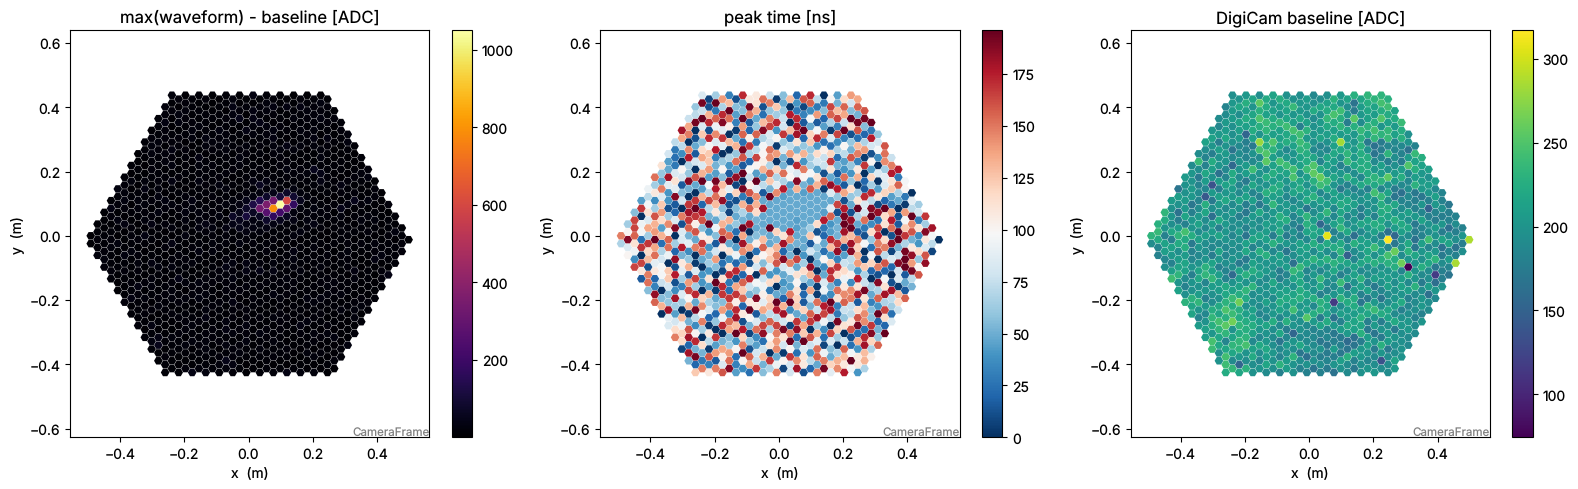

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

r0 = shower_event.r0.tel[tel_id]
image = r0.waveform[0].max(axis=1) - r0.pedestal
display = CameraDisplay(geometry, image=image, ax=axes[0], title="max(waveform) - baseline [ADC]")
display.add_colorbar(ax=axes[0])

peak_time = r0.waveform[0].argmax(axis=1) / sampling_rate.to_value(u.GHz)
display = CameraDisplay(geometry, image=peak_time, ax=axes[1], title="peak time [ns]", cmap="RdBu_r")
display.add_colorbar(ax=axes[1])

display = CameraDisplay(geometry, image=r0.pedestal, ax=axes[2], title="DigiCam baseline [ADC]", cmap="viridis")
display.add_colorbar(ax=axes[2])
plt.tight_layout()

### Trigger traces

The trigger input traces (432 trigger patches) and the trigger outputs of the clusters of 7 and 19 patches and of
the muon trigger are also stored, as `(n_patches, n_samples)` arrays (filled with `nan` when absent from the file).
They are in patch order (`patch_sw_id`, the patch of 3 pixels `DigiCam.patch_matrix`, the central patch for the outputs):
the reader takes care of the order of the camera sectors of each telescope (`sst1mpipe.constants.TRIGGER_SECTOR_ORDER`)
and of the wrongly connected modules, as for the pixels.
The outputs are 0/1: here the event was triggered by the 7 patch clusters (camera event type `PATCH7`).

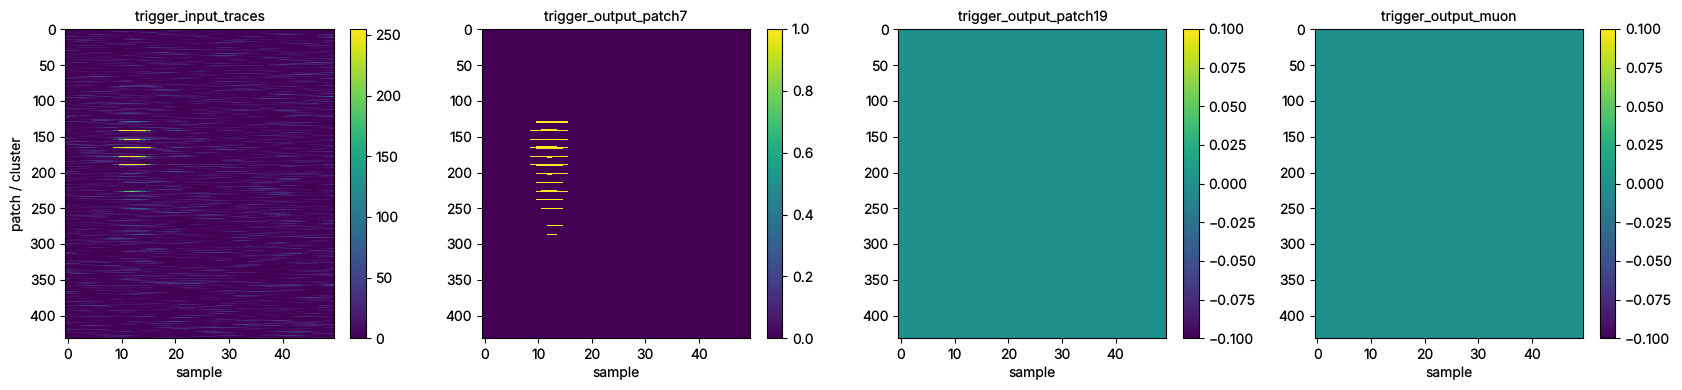

In [24]:
r0 = shower_event.r0.tel[tel_id]
names = ["trigger_input_traces", "trigger_output_patch7", "trigger_output_patch19", "trigger_output_muon"]
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, name in zip(axes, names, strict=True):
    traces = getattr(r0, name)
    im = ax.imshow(traces, aspect="auto", interpolation="none")
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("sample")
    fig.colorbar(im, ax=ax)
axes[0].set_ylabel("patch / cluster")
plt.tight_layout()

## 5. Run level summaries

The events are read one by one, so it is easy to collect a few quantities over the whole run:
event types, event times, baselines...

In [25]:
rows = []
with EventSource(input_file) as source:
    for event in source:
        r0 = event.r0.tel[source.tel_id]
        rows.append({
            "event_id": event.index.event_id,
            "camera_event_number": r0.camera_event_number,
            "time": event.trigger.time.unix_tai,
            "event_type": event.trigger.event_type.name,
            "camera_event_type": str(r0.event_type),
            "mean_baseline": r0.pedestal.mean(),
            "max_adc": r0.waveform.max(),
        })
events = Table(rows)
events["dt"] = np.diff(events["time"], prepend=events["time"][0]) * 1e3
events["dt"].unit = u.ms
events[:10]

event_id,camera_event_number,time,event_type,camera_event_type,mean_baseline,max_adc,dt
,,,,,,,ms
int64,int64,float64,str12,str24,float64,int16,float64
25085123,3612333,1768964826.7464712,SUBARRAY,CameraEventType.PATCH7,204.08931327160494,330,0.0
25085126,3612334,1768964826.7513413,SUBARRAY,CameraEventType.PATCH7,203.91575038580248,332,4.870176315307617
25085127,3612335,1768964826.7517002,SUBARRAY,CameraEventType.PATCH7,203.90586419753086,331,0.35881996154785156
25085129,3612336,1768964826.7549167,SKY_PEDESTAL,CameraEventType.INTERNAL,204.06394675925927,327,3.2165050506591797
25085133,3612337,1768964826.7649167,SKY_PEDESTAL,CameraEventType.INTERNAL,203.9892939814815,324,9.999990463256836
25085136,3612338,1768964826.7697473,SUBARRAY,CameraEventType.PATCH7,203.92447916666666,327,4.830598831176758
25085137,3612339,1768964826.7706814,SUBARRAY,CameraEventType.PATCH7,203.83858989197532,334,0.9341239929199219
25085140,3612340,1768964826.7749166,SKY_PEDESTAL,CameraEventType.INTERNAL,204.0570023148148,343,4.235267639160156


In [26]:
print(collections.Counter(events["event_type"]))
print(collections.Counter(events["camera_event_type"]))
duration = events["time"][-1] - events["time"][0]
print(f"{len(events)} events in {duration:.3f} s -> {len(events) / duration:.1f} Hz")

Counter({'SUBARRAY': 22, 'SKY_PEDESTAL': 13})
Counter({'CameraEventType.PATCH7': 22, 'CameraEventType.INTERNAL': 13})
35 events in 0.128 s -> 272.5 Hz


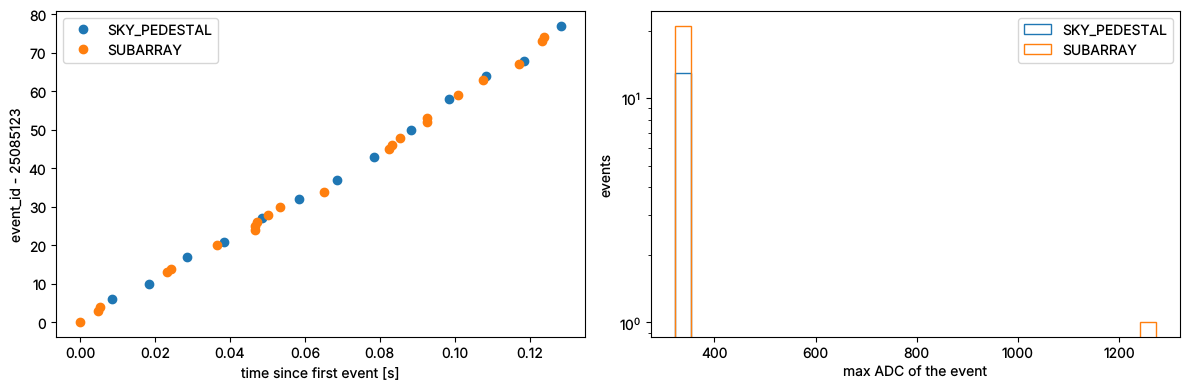

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
t0, id0 = events["time"][0], events["event_id"][0]
bins = np.histogram_bin_edges(events["max_adc"], bins=30)
for event_type in np.unique(events["event_type"]):
    mask = events["event_type"] == event_type
    axes[0].plot(events["time"][mask] - t0, events["event_id"][mask] - id0, "o", label=event_type)
    axes[1].hist(events["max_adc"][mask], bins=bins, histtype="step", label=event_type)
axes[0].set(xlabel="time since first event [s]", ylabel=f"event_id - {id0}")
axes[1].set(xlabel="max ADC of the event", ylabel="events", yscale="log")
for ax in axes:
    ax.legend()
plt.tight_layout()

## 6. Under the hood: the raw zfits file

The event source reads the files with `protozfits`. If you need a field of the DigiCam `CameraEvent` protobuf message
which is not copied to the ctapipe containers, you can read the file directly. Each row of the `Events` table is a
named tuple; the most useful fields are listed below (see `sst1mpipe.io.sst1m_event_source.fill_r0_event`
for how they are converted).

In [28]:
with fits.open(input_file) as hdul:
    hdul.info()

Filename: sst1mpipe/resources/test_data/zfits/SST1M2_20260120_1102.fits.fz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       8   ()      
  1  DigicamConfig    1 BinTableHDU    122   1R x 15C   [1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB]   
  2  Events        1 BinTableHDU    210   1R x 33C   [1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB, 1QB]   


In [29]:
header = fits.getheader(input_file, "Events")
for key in ["TARGET", "PBFHEAD", "DATE", "DATEEND", "ZNAXIS2"]:
    print(f"{key:8s} = {header.get(key)!r:40s} / {header.comments[key]}")

TARGET   = 'MRK421_W1,166.994800,38.105300'         / Current Target
PBFHEAD  = 'DataModel.CameraEvent'                  / Written message name
DATE     = '2026-01-21T03:06:31'                    / File creation date
DATEEND  = '2026-01-21T03:06:31'                    / File closing date
ZNAXIS2  = 35                                       / Number of uncompressed rows


In [30]:
from protozfits import File

with File(str(input_file)) as f:
    print(f)
    raw_event = next(iter(f.Events))

print("telescopeID       :", raw_event.telescopeID)
print("eventNumber       :", raw_event.eventNumber, "(-> r0.camera_event_number)")
print("arrayEvtNum       :", raw_event.arrayEvtNum, "(SWAT event id -> index.event_id)")
print("event_type        :", raw_event.event_type, "->", CameraEventType(raw_event.event_type))
print("local time        :", raw_event.local_time_sec, "s", raw_event.local_time_nanosec, "ns")
waveforms = raw_event.hiGain.waveforms
print("hiGain.waveforms  :", waveforms._fields)
print("samples           :", waveforms.samples.shape, "(n_pixels * n_samples, flat, unsorted pixels)")
print("pixelsIndices     :", waveforms.pixelsIndices[:10], "...")
print("baselines         :", waveforms.baselines[:5], "(/ 16 -> r0.pedestal)")

File({'DigicamConfig': Table(1xDataModel.DigicamConfig), 'Events': Table(35xDataModel.CameraEvent)})
telescopeID       : 22
eventNumber       : 3612333 (-> r0.camera_event_number)
arrayEvtNum       : 25085123 (SWAT event id -> index.event_id)
event_type        : 1 -> CameraEventType.PATCH7
local time        : 1768964826 s 746471248 ns
hiGain.waveforms  : ('samples', 'pixelsIndices', 'firstSplIdx', 'num_samples', 'baselines', 'peak_time_pos', 'time_over_threshold')
samples           : (64800,) (n_pixels * n_samples, flat, unsorted pixels)
pixelsIndices     : [146 117 177 145 213 178 179 147 249 250] ...
baselines         : [3622 3136 3571 3810 3405] (/ 16 -> r0.pedestal)


## Going further

* `sst1mpipe-process` runs the full chain R0 -> DL1 on these files (R0 -> R1 calibration, image extraction, cleaning,
  Hillas parameters) and writes the ctapipe DL1 format.
* `sst1mpipe-monitoring` computes the pedestal statistics and the pointing, read back by the `SST1MMonitoringSource`
  into `event.monitoring`.
* `notebooks/sst1m_raw_r0_r1.ipynb` shows the R0 -> R1 calibration.